# Introduccion al procesamiento de Audio

## Librerias

In [ ]:
import numpy as np
import scipy.fftpack as fft
import matplotlib.pyplot as plt
import torch
import torchaudio
import torch.nn as nn
import torchaudio.transforms as T
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from torch.utils.data import random_split
import IPython
from pathlib import Path
import os

In [ ]:
# 1. Configurar dispositivo (GPU si está disponible, si no CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando el dispositivo: {device}")

Usando el dispositivo: cuda


In [ ]:
audio, sample_rate = torchaudio.load("/content/174-84280-0002.flac")
audio = audio.squeeze()
print(f"audio = {audio}")
print("Sampling Rate:", sample_rate)
print("Total Samples in Audio:", len(audio))
print("Total Duration:", len(audio) / sample_rate, "seconds")

IPython.display.Audio(audio, rate=sample_rate)

audio = tensor([-0.0004, -0.0006, -0.0007,  ..., -0.0002, -0.0003, -0.0002])
Sampling Rate: 16000
Total Samples in Audio: 195200
Total Duration: 12.2 seconds


## Imagen audio

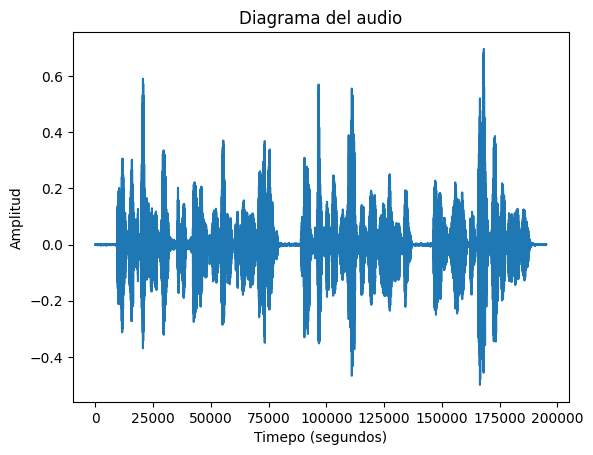

In [ ]:
plt.plot(audio)
plt.xlabel("Timepo (segundos)")
plt.ylabel("Amplitud")
plt.title("Diagrama del audio")
plt.show()

## Transformada Discreta de Fourier (DFT)

$$
g(k) = \mathcal{F}\{g(n)\} = \sum_{n=0}^{N-1} g_n[n] \cdot e^{-j n k \frac{2\pi}{N}}
$$


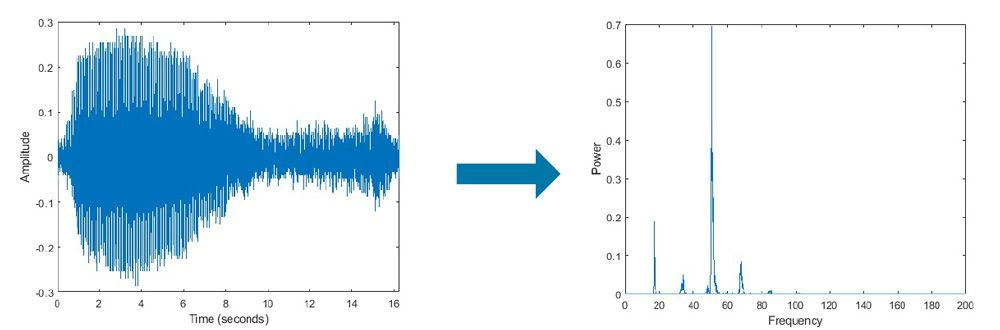

Esta ecuación corresponde específicamente a la **Transformada Discreta de Fourier (DFT)**, que es la versión utilizada por las computadoras para procesar señales digitales, como archivos de audio `.flac`.

- **$g[n]$ (La entrada):** Es la señal original en el dominio del tiempo. Cada $n$ representa una muestra de la señal (un valor numérico). Por ejemplo, si tu audio dura 1 segundo y tiene una tasa de muestreo de 16,000 Hz, tendrás $N = 16,000$ muestras individuales, donde $n$ va desde $0$ hasta $15,999$.

- **$g(k)$ (La salida):** Es el resultado en el dominio de la frecuencia. Cada valor de $k$ representa un componente de frecuencia específico, conocido como *frequency bin*. En otras palabras, cada componente indica cuánto contribuye una frecuencia determinada a la señal original.

- **$\sum_{n=0}^{N-1}$ (La sumatoria):** Significa que, para calcular el componente correspondiente a una frecuencia $k$, debemos analizar todas las muestras de la señal y sumar sus contribuciones.

- **$e^{-j n k \frac{2\pi}{N}}$ (El oscilador complejo):** Es el elemento fundamental de la transformación. Utilizando la fórmula de Euler, sabemos que:

  $$e^{-j\theta} = \cos(\theta) - j\sin(\theta)$$

  Por lo tanto, este término representa una combinación de una función coseno y una función seno, ambas asociadas a una frecuencia determinada por $k$.

  El símbolo $j$ representa la unidad imaginaria ($j = \sqrt{-1}$). Su utilización permite representar tanto la magnitud como la fase de los componentes de frecuencia.

**Una precisión importante:** La DFT no identifica simplemente las frecuencias presentes en el audio; también calcula sus magnitudes y fases. Esto permite reconstruir la señal original a partir de sus componentes de frecuencia.

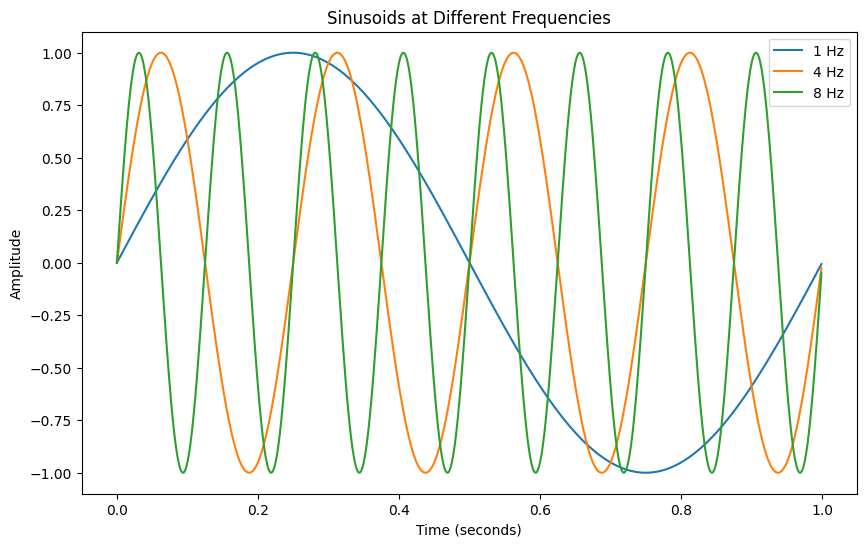

In [ ]:
# Define parameters
t = np.linspace(0, 1, 1000, endpoint=False)  # Time vector (1 second, 1000 samples)
frequencies = [1, 4, 8]  # Different frequencies in Hz

# Plot sinusoids
plt.figure(figsize=(10, 6))
for f in frequencies:
    y = np.sin(2 * np.pi * f * t)
    plt.plot(t, y, label=f'{f} Hz')

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Sinusoids at Different Frequencies')
plt.legend()
plt.show()

In [ ]:
gn = [0, 1, 2, 3, 4]
gk = fft.fft(gn)
print(gk)

[10. -0.j         -2.5+3.4409548j  -2.5+0.81229924j -2.5-0.81229924j
 -2.5-3.4409548j ]


In [ ]:
M_gk = abs(gk)
ph_gk = np.angle(gk)
print('Magnitud: ', M_gk)
print('Angle: ', ph_gk*180/np.pi)

Magnitud:  [10.          4.25325404  2.62865556  2.62865556  4.25325404]
Angle:  [  -0.  126.  162. -162. -126.]


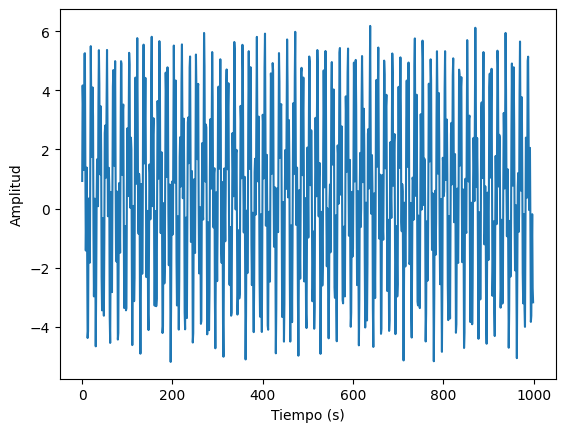

In [ ]:
Ts = 0.001 # tiempo
Fs = 1/Ts # frecuncia
w1 = 2*np.pi*60 # frecuencia de la señal 1
w2 = 2*np.pi*223 # frecuncia de la señal 2

n = Ts*np.arange(0, 1000)
ruido = np.random.random(len(n))
x = 3*np.sin(w1*n)+2.3*np.sin(w2*n)+ruido # señal compuesta

plt.plot(x)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.show()

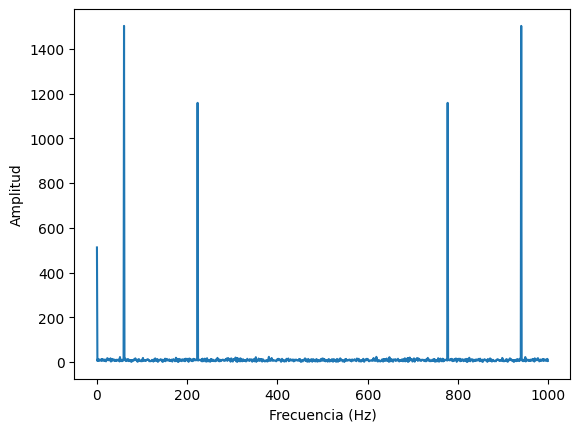

In [ ]:
gk = fft.fft(x) # calculamos la transformada
M_gk = abs(gk) # magnitud

F = Fs*np.arange(0, len(x))/len(x) # vector de frecuencias

plt.plot(F, M_gk)
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.show()

## Devuelta al audio original

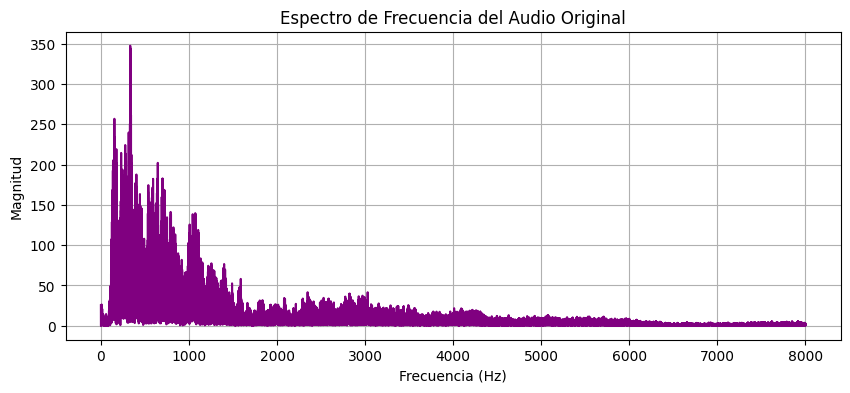

In [ ]:
gk_audio = fft.fft(audio.numpy()) #  Calculamos la transformada de Fourier del audio

# Obtenemos la magnitud
M_gk_audio = abs(gk_audio)

# Creamos el vector de frecuencias correspondiente al audio
# Usamos la tasa de muestreo real del audio (16000 Hz)
F_audio = sample_rate * np.arange(0, len(audio)) / len(audio)

# 4. Graficamos el espectro (solo la primera mitad para visualizar frecuencias positivas)
mitad = len(audio) // 2

plt.figure(figsize=(10, 4))
plt.plot(F_audio[:mitad], M_gk_audio[:mitad], color='purple')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud')
plt.title('Espectro de Frecuencia del Audio Original')
plt.grid(True)
plt.show()

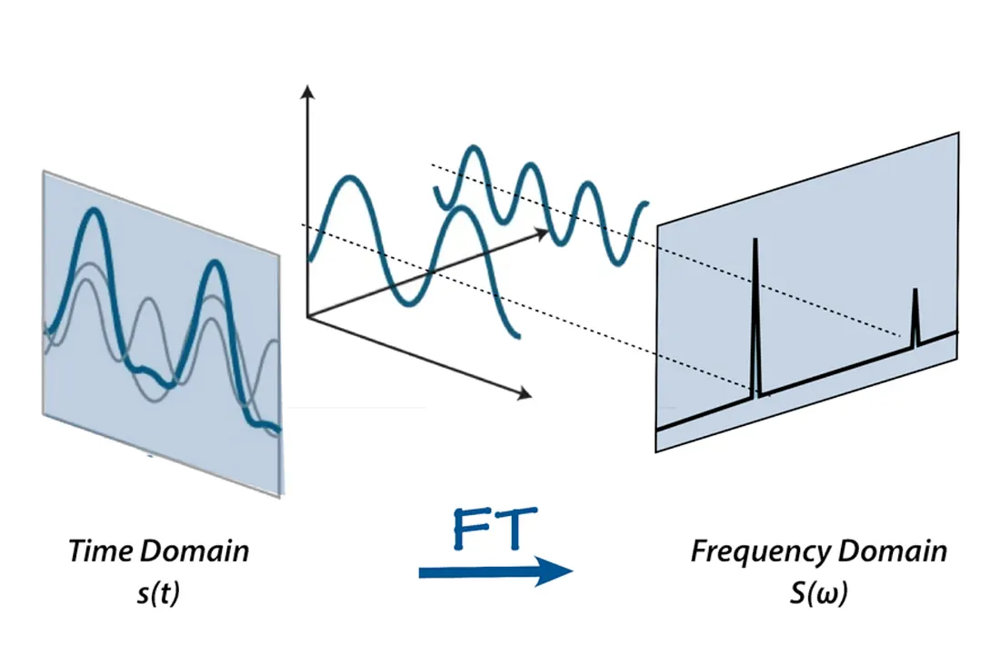

In [ ]:
mitad = len(audio) // 2
indice_maximo = np.argmax(M_gk_audio[:mitad])

# Obtener la frecuencia y magnitud correspondientes
frecuencia_dominante = F_audio[indice_maximo]
magnitud_maxima = M_gk_audio[indice_maximo]

print(f"La mayor magnitud en el espectro de frecuencia es: {magnitud_maxima:.4f}")
print(f"Esta magnitud ocurre a la frecuencia dominante de: {frecuencia_dominante:.2f} Hz")

La mayor magnitud en el espectro de frecuencia es: 347.4050
Esta magnitud ocurre a la frecuencia dominante de: 333.36 Hz


## Nyquist-Shannon Sampling Theorem

El teorema de muestreo de Nyquist-Shannon establece la frecuencia de muestreo mínima necesaria para representar una señal continua sin perder información sobre sus componentes de frecuencia.

El teorema afirma que la frecuencia de muestreo debe ser superior al doble de la frecuencia máxima presente en la señal original:

$$
f_s > 2f_{\text{max}}
$$

Donde:

$f_s$: (Frecuencia de muestreo): Número de muestras capturadas por segundo, medida en hercios (Hz).

$f_{\text{max}}$: (Frecuencia máxima): Componente de frecuencia más alta presente en la señal original.

$2f_{\text{max}}$: Frecuencia de muestreo teórica mínima necesaria para representar la señal sin aliasing.

En otras palabras, necesitamos al menos dos muestras por ciclo de la frecuencia más alta que deseamos preservar.



**¿Por qué es esto importante para el procesamiento de audio?**

El audio digital se representa como una secuencia de muestras discretas. Si la frecuencia de muestreo es demasiado baja, algunos componentes de frecuencia no pueden representarse correctamente. Esto puede provocar un fenómeno conocido como *aliasing* (solapamiento), en el que las frecuencias más altas aparecen como frecuencias más bajas en la señal muestreada.

Por ejemplo, el oído humano suele percibir frecuencias de hasta aproximadamente 20 000 Hz. Por ello, en la grabación de música se utiliza habitualmente una frecuencia de muestreo de 44 100 Hz, lo que permite representar frecuencias de hasta unos 22 050 Hz en condiciones de muestreo ideales.

Para el procesamiento de voz, se emplean a menudo frecuencias de muestreo más bajas, como 16 000 Hz, ya que suelen ser suficientes para tareas relacionadas con el habla.

Relación con las redes neuronales convolucionales (CNN): antes de introducir audio en una red neuronal convolucional, debemos asegurarnos de que las señales de entrada tengan una frecuencia de muestreo adecuada y coherente. Esto ayuda a preservar la información de frecuencia relevante y garantiza que el modelo reciba representaciones de audio uniformes.

In [ ]:
audio, sample_rate = torchaudio.load("/content/174-84280-0002.flac")

# 2. Convertir a mono de forma segura evaluando las dimensiones reales
if audio.ndim > 1 and audio.shape[0] > 1:
    # Si tiene más de un canal (estéreo/multicanal), promediamos los canales
    audio = audio.mean(dim=0)
else:
    # Si ya es mono, nos aseguramos de quitar dimensiones de tamaño 1 sobrantes
    audio = audio.squeeze()

# 3. Extraer información del audio de manera robusta usando .numel()
num_samples = audio.numel()
duration = num_samples / sample_rate
nyquist_frequency = sample_rate / 2

print(f"Sampling Rate: {sample_rate} Hz")
print(f"Total Samples: {num_samples}")
print(f"Duration: {duration:.2f} seconds")
print(f"Nyquist Frequency: {nyquist_frequency} Hz")

Sampling Rate: 16000 Hz
Total Samples: 195200
Duration: 12.20 seconds
Nyquist Frequency: 8000.0 Hz


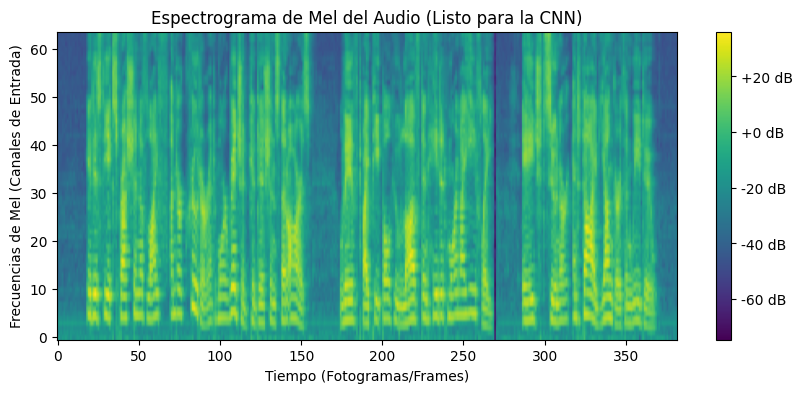

Dimensiones de la imagen generada: torch.Size([1, 64, 382])


In [ ]:
# 1. Definimos la transformación para extraer el Espectrograma de Mel
mel_spectrogram_transform = T.MelSpectrogram(
    sample_rate=sample_rate, # cantidad de muestras
    n_fft=1024, # recortar el audio en pequeños trazos (1024 muestras).
    hop_length=512, # ventana de las siguientes 512 muestras
    n_mels=64 # cantidad de canales del audio (64 pixeles en la imagen)
)

# 2. Aplicamos la transformación al audio (agregamos una dimensión de lote si es necesario)
# Las transformaciones de PyTorch esperan un formato (canales, tiempo)
if audio.ndim == 1:
    mel_spec = mel_spectrogram_transform(audio.unsqueeze(0))
else:
    mel_spec = mel_spectrogram_transform(audio)

# 3. Convertimos la amplitud a escala logarítmica (Decibelios), que es más natural para el oído y la red
mel_spec_db = T.AmplitudeToDB()(mel_spec)

# 4. Graficamos el espectrograma como una imagen
plt.figure(figsize=(10, 4))
plt.imshow(mel_spec_db.squeeze().numpy(), origin='lower', aspect='auto', cmap='viridis')
plt.title('Espectrograma de Mel del Audio (Listo para la CNN)')
plt.xlabel('Tiempo (Fotogramas/Frames)')
plt.ylabel('Frecuencias de Mel (Canales de Entrada)')
plt.colorbar(format='%+2.0f dB')
plt.show()

print(f"Dimensiones de la imagen generada: {mel_spec_db.shape}")

### ¿Qué es exactamente este "Espectrograma de Mel" que acabamos de graficar?

Si ves la imagen de arriba y te parece un mapa de calor extraño, no te preocupes. Vamos a explicarlo de forma muy sencilla y sin tecnicismos raros.

#### 1. El "problema" de nuestros oídos
Los humanos no escuchamos las frecuencias de manera matemática o lineal.
* Si pasamos de **100 Hz a 200 Hz** (tonos muy graves), notarás un cambio enorme de tono.
* Pero si pasamos de **10,000 Hz a 10,100 Hz** (tonos muy agudos), para tu oído sonarán prácticamente iguales, aunque físicamente la diferencia sigue siendo de 100 Hz.

En resumen: **somos muy sensibles a los cambios en los sonidos graves y bastante sordos a los cambios en los sonidos agudos.**

Para que la computadora entienda el sonido tal como lo percibimos nosotros, los científicos inventaron la **Escala de Mel**. Esta escala simplemente deforma las frecuencias reales para que coincidan con nuestra percepción humana.

#### 2. ¿Cómo se construye esta imagen paso a paso?
Imagina que tu audio de 12 segundos es una tira larga de película. Para hacer el espectrograma, hacemos lo siguiente:
1. **Cortamos el audio en rodajas muy finas** (de unos pocos milisegundos).
2. A cada rodaja **le aplicamos Fourier** para saber qué notas (frecuencias) suenan en ese instante preciso.
3. **Acomodamos esas frecuencias usando la Escala Mel** (dándole más espacio a los graves abajo, y agrupando los agudos arriba).
4. **Pegamos todas las rodajas en orden cronológico**.

#### 3. ¿Cómo leer la gráfica resultante?
* **Eje Horizontal (Tiempo):** Es el transcurso del audio. De izquierda a derecha avanzan los segundos.
* **Eje Vertical (Frecuencia Mel):** Abajo están los sonidos graves (tonos bajos) y arriba los agudos (tonos altos).
* **El Color (Energía/Volumen):** Los colores brillantes (amarillos y verdes) son los momentos donde hay sonido fuerte en esa frecuencia. El fondo oscuro (morado y azul) representa silencio.

**¿Por qué esto es perfecto para entrenar una CNN?**
Una red neuronal convolucional (CNN) es increíblemente buena buscando patrones en imágenes (como bordes, curvas o texturas).

Al convertir el audio en un Espectrograma de Mel, transformamos un problema de sonido en un **problema de visión**. Para la CNN, clasificar tu audio ahora es tan fácil como identificar si en una foto hay un gato o un perro, ya que cada sonido deja una "huella visual" única en la gráfica.

Como tu audio se grabó a 16000 Hz, la frecuencia máxima de Nyquist del archivo puede contener de forma segura y real es de $8000\text{ Hz}$

# Arquitectura de la red neuronal

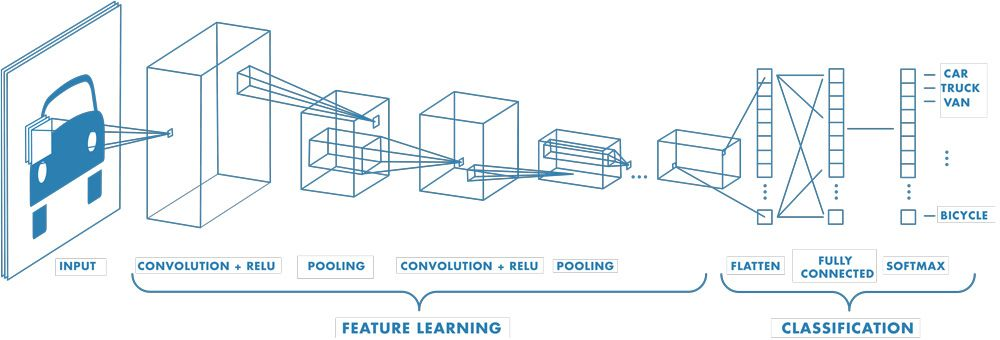

# Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("whats2000/human-screaming-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.17G/4.17G [00:53<00:00, 84.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/whats2000/human-screaming-detection-dataset/versions/2


## Preparacion


In [ ]:
def load_audio_files(path: str, label: str, limit: int = None):
  dataset = []
  w = sorted(str(p) for p in Path(path).glob('*.wav'))

  if limit is not None:
    w = w[:limit]

  for i, file_path in enumerate(w):
    path, filename = os.path.split(file_path)
    name, _ = os.path.splitext(filename)
    waveform, sample_rate = torchaudio.load(file_path)
    entry = {'waveform': waveform, 'sample_rate': sample_rate, 'label': label, 'id': i}
    dataset.append(entry)
  return dataset

print("--- Estructura de directorios del dataset ---")
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}[Carpeta] {os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files[:3]:
        print(f"{subindent}{f}")
    if len(files) > 3:
        print(f"{subindent}... y {len(files) - 3} archivos más.")

--- Estructura de directorios del dataset ---
[Carpeta] 2/
    [Carpeta] NotScreaming/
        25TiEJB46Qg_out.wav
        WQvdabO-0yw_out.wav
        3X4t1yXiR64_out.wav
        ... y 2628 archivos más.
    [Carpeta] Screaming/
        zhAUkNhQ7uM_out.wav
        eAQC9olONU4_out.wav
        XF-dkAiAKnc_out.wav
        ... y 859 archivos más.


In [ ]:
screaming_dataset = load_audio_files(os.path.join(path, 'Screaming'), 'Screaming', limit=500)
not_screaming_dataset  = load_audio_files(os.path.join(path, 'NotScreaming'), 'NotScreaming', limit=500)

print(f"¡Carga lista!")
print(f"Audios de Gritos (Screaming): {len(screaming_dataset)} cargados.")
print(f"Audios sin Gritos (NotScreaming): {len(not_screaming_dataset)} cargados.")

¡Carga lista!
Audios de Gritos (Screaming): 500 cargados.
Audios sin Gritos (NotScreaming): 500 cargados.


In [ ]:
screaming_dataset[:5]

[{'waveform': tensor([[0.0000, 0.0000, 0.0000,  ..., 0.0573, 0.1068, 0.0877],
          [0.0000, 0.0000, 0.0000,  ..., 0.0573, 0.1068, 0.0877]]),
  'sample_rate': 44100,
  'label': 'Screaming',
  'id': 0},
 {'waveform': tensor([[-0.2336, -0.2152, -0.1715,  ..., -0.1474, -0.1485, -0.1496],
          [-0.2410, -0.2266, -0.2237,  ..., -0.0788, -0.0812, -0.0795]]),
  'sample_rate': 44100,
  'label': 'Screaming',
  'id': 1},
 {'waveform': tensor([[0.0976, 0.1692, 0.2065,  ..., 0.1551, 0.2217, 0.2664],
          [0.1116, 0.1799, 0.2049,  ..., 0.1391, 0.2158, 0.2742]]),
  'sample_rate': 44100,
  'label': 'Screaming',
  'id': 2},
 {'waveform': tensor([[-0.6388, -0.6234, -0.4489,  ..., -0.2263, -0.2391, -0.2776],
          [-0.6207, -0.6150, -0.4537,  ..., -0.1915, -0.2045, -0.2404]]),
  'sample_rate': 44100,
  'label': 'Screaming',
  'id': 3},
 {'waveform': tensor([[-1.7645e-01, -2.0004e-01, -2.0139e-01,  ..., -6.1035e-05,
           -6.1035e-05, -6.1035e-05]]),
  'sample_rate': 44100,
  'labe

In [ ]:
not_screaming_dataset[:5]

[{'waveform': tensor([[-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374],
          [-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374]]),
  'sample_rate': 44100,
  'label': 'NotScreaming',
  'id': 0},
 {'waveform': tensor([[-0.0004, -0.0004, -0.0002,  ...,  0.0002, -0.0002, -0.0005],
          [-0.0004, -0.0004, -0.0002,  ...,  0.0002, -0.0002, -0.0005]]),
  'sample_rate': 44100,
  'label': 'NotScreaming',
  'id': 1},
 {'waveform': tensor([[-0.0060, -0.0005,  0.0016,  ..., -0.0117, -0.0117, -0.0127],
          [-0.0154, -0.0064, -0.0031,  ..., -0.0116, -0.0118, -0.0125]]),
  'sample_rate': 44100,
  'label': 'NotScreaming',
  'id': 2},
 {'waveform': tensor([[ 0.0067,  0.0037, -0.0010,  ...,  0.0002,  0.0002,  0.0002],
          [ 0.0062,  0.0032, -0.0014,  ...,  0.0002,  0.0002,  0.0002]]),
  'sample_rate': 44100,
  'label': 'NotScreaming',
  'id': 3},
 {'waveform': tensor([[-0.0518, -0.0407, -0.0268,  ..., -0.0185, -0.0204, -0.0233],
          [-0.0801, -0.0845, -0.

## Exploración

In [ ]:
scream_id = 5
no_scream_id = 0

screaming_waveform = screaming_dataset[scream_id]['waveform']
screaming_sample_rate = screaming_dataset[scream_id]['sample_rate']

print(f'Screaming Waveform: {screaming_waveform}')
print(f'Screaming Sample Rate: {screaming_sample_rate}')
print(f'Screaming Label: {screaming_dataset[scream_id]["label"]}')
print(f'Screaming ID: {screaming_dataset[scream_id]["id"]} \n')


not_screaming_waveform = not_screaming_dataset[no_scream_id]['waveform']
not_screaming_sample_rate = not_screaming_dataset[no_scream_id]['sample_rate']


print(f'Screaming Waveform: {not_screaming_waveform}')
print(f'Screaming Sample Rate: {not_screaming_sample_rate}')
print(f'Screaming Label: {not_screaming_dataset[no_scream_id]["label"]}')
print(f'Screaming ID: {not_screaming_dataset[no_scream_id]["id"]} \n')

Screaming Waveform: tensor([[ 0.0032, -0.0081, -0.0218,  ..., -0.0014, -0.0021, -0.0023],
        [ 0.0032, -0.0081, -0.0218,  ..., -0.0014, -0.0021, -0.0023]])
Screaming Sample Rate: 44100
Screaming Label: Screaming
Screaming ID: 5 

Screaming Waveform: tensor([[-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374],
        [-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374]])
Screaming Sample Rate: 44100
Screaming Label: NotScreaming
Screaming ID: 0 



In [ ]:
def show_waveform(waveform, sample_rate, label):
  print("Waveform: {}\nSample rate: {}\nLabels: {} \n".format(waveform, sample_rate, label))
  # calculamos nueva tasa de muestreo
  new_sample_rate = sample_rate / 10
  # nos quedamos con el canal izquierdo
  channel = 0
  waveform_transformed = torchaudio.transforms.Resample(sample_rate, new_sample_rate)(waveform[channel, :].view(1, -1))
  print("Tamaño del forma de onda transformada: {}\nSample rate: {}".format(waveform_transformed.size(), new_sample_rate))

  # grafica de la señal del audio
  plt.figure()
  plt.plot(waveform_transformed[0, :].numpy())

Waveform: tensor([[ 0.0032, -0.0081, -0.0218,  ..., -0.0014, -0.0021, -0.0023],
        [ 0.0032, -0.0081, -0.0218,  ..., -0.0014, -0.0021, -0.0023]])
Sample rate: 44100
Labels: Screaming 

Tamaño del forma de onda transformada: torch.Size([1, 44100])
Sample rate: 4410.0


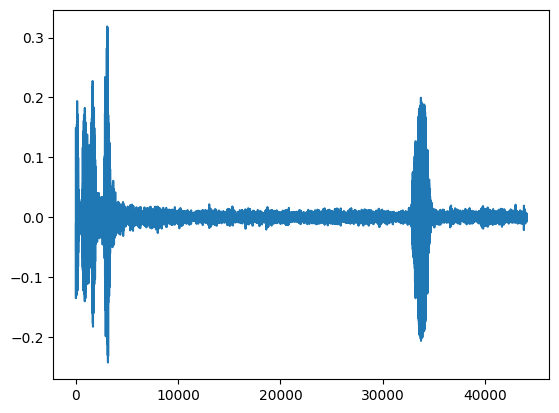

In [ ]:
# muestra de audio screaming dataset
show_waveform(screaming_waveform, screaming_sample_rate, 'Screaming')
IPython.display.Audio(screaming_waveform.numpy(), rate=screaming_sample_rate)

Waveform: tensor([[-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374],
        [-0.0436, -0.0533, -0.0568,  ...,  0.0986,  0.1464,  0.1374]])
Sample rate: 44100
Labels: NotScreaming 

Tamaño del forma de onda transformada: torch.Size([1, 44100])
Sample rate: 4410.0


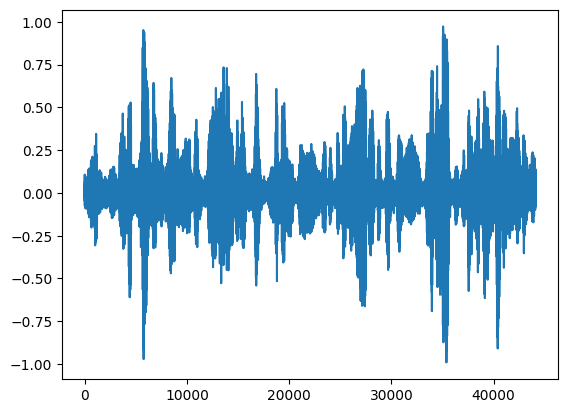

In [ ]:
show_waveform(not_screaming_waveform, not_screaming_sample_rate, 'NotScreaming')
IPython.display.Audio(not_screaming_waveform.numpy(), rate=not_screaming_sample_rate)

In [ ]:
def show_spectrogram(waveform_classA, waveform_classB):
    # Compute the spectrogram for the first waveform (class A)
    yes_spectrogram = torchaudio.transforms.Spectrogram()(waveform_classA)
    print("\nShape of yes spectrogram: {}".format(yes_spectrogram.size()))

    # Compute the spectrogram for the second waveform (class B)
    no_spectrogram = torchaudio.transforms.Spectrogram()(waveform_classB)
    print("Shape of no spectrogram: {}".format(no_spectrogram.size()))

    # Creacion de visualización
    plt.figure()

    # subplot de la clase A (Izquierda)
    plt.subplot(1, 2, 1)
    plt.xlabel("Tiempo")
    plt.ylabel("Frecuencia")
    plt.title("Features of {}".format('Screaming'))
    plt.imshow(yes_spectrogram.log2()[0, :, :].numpy(), cmap='viridis', aspect='auto')

    # subplot clase B (Derecha)
    plt.subplot(1, 2, 2)
    plt.xlabel("Tiempo")
    plt.ylabel("Frecuencia")
    plt.title("Features of {}".format('NotScreaming'))
    plt.imshow(no_spectrogram.log2()[0, :, :].numpy(), cmap='viridis', aspect='auto')


Shape of yes spectrogram: torch.Size([2, 201, 2206])
Shape of no spectrogram: torch.Size([2, 201, 2206])


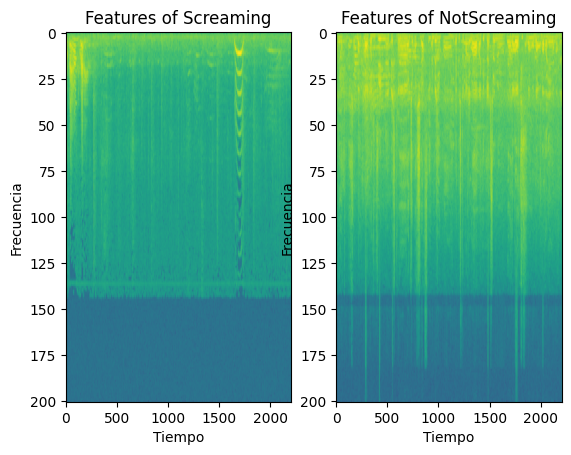

In [ ]:
show_spectrogram(screaming_waveform, not_screaming_waveform)

In [ ]:
display(IPython.display.Audio(screaming_waveform.numpy(), rate=screaming_sample_rate))
display(IPython.display.Audio(not_screaming_waveform.numpy(), rate=not_screaming_sample_rate))

## Dataset

In [ ]:
total_dataset = screaming_dataset + not_screaming_dataset

class CustomAudioDataset(Dataset):
  def __init__(self, dataset_list, target_sample_rate=16000, max_ms=10000, n_mels=64):
    super().__init__()
    self.dataset = dataset_list
    self.target_sample_rate = target_sample_rate
    self.max_samples = int(self.target_sample_rate * (max_ms / 1000))
    self.mel_transform = T.MelSpectrogram(
        sample_rate=self.target_sample_rate,
        n_fft=1024,
        hop_length=512,  # Esto nos dará ~313 frames de tiempo para 10 segundos de audio
        n_mels=n_mels
    )
    self.db_transform = T.AmplitudeToDB()

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, idx):
    entry = self.dataset[idx]
    waveform = entry['waveform']
    sr = entry['sample_rate']
    label_str = entry['label']

    # 1. Convertir a Mono si tiene más de 1 canal
    if waveform.shape[0] > 1:
      waveform = waveform[0:1, :]

    # 2. Resamplear si la tasa original no coincide con la objetivo
    if sr != self.target_sample_rate:
      resample_transform = T.Resample(sr, self.target_sample_rate)
      waveform = resample_transform(waveform)

    # 3. Homogeneizar el tamaño de forma consistente usando self.max_samples
    num_channels, num_samples = waveform.shape
    if num_samples > self.max_samples:
       waveform = waveform[:, :self.max_samples]
    elif num_samples < self.max_samples:
       pad_len = self.max_samples - num_samples
       pad = torch.zeros((num_channels, pad_len))
       waveform = torch.cat([waveform, pad], dim=1)

    # 4. Extraer el Espectrograma de Mel y pasarlo a escala Logarítmica
    mel_spec = self.mel_transform(waveform)
    mel_spec_db = self.db_transform(mel_spec)

    # 5. Etiqueta numérica
    label = 1 if label_str == 'Screaming' else 0

    return mel_spec_db, label

audio_dataset_ready = CustomAudioDataset(total_dataset)
print(f"(Ahora tiene una resolución temporal correcta de 313 frames en lugar de 32)")

(Ahora tiene una resolución temporal correcta de 313 frames en lugar de 32)


In [ ]:
def get_and_listen_audio(dataset_list, idx, target_sample_rate=16000, max_ms=10000):
    entry = dataset_list[idx]
    waveform = entry['waveform']
    sr = entry['sample_rate']
    label_str = entry['label']

    # 1. Convertir a Mono
    if waveform.shape[0] > 1:
        waveform = waveform[0:1, :]

    # 2. Resamplear a la tasa objetivo
    if sr != target_sample_rate:
        resample_transform = T.Resample(sr, target_sample_rate)
        waveform = resample_transform(waveform)

    # 3. Homogeneizar el tamaño (recortar o rellenar con ceros)
    max_samples = int(target_sample_rate * (max_ms / 1000))
    num_channels, num_samples = waveform.shape
    if num_samples > max_samples:
        waveform = waveform[:, :max_samples]
    elif num_samples < max_samples:
        pad_len = max_samples - num_samples
        pad = torch.zeros((num_channels, pad_len))
        waveform = torch.cat([waveform, pad], dim=1)

    print(f"ID: {idx} | Clase: {label_str} | Tamaño final de onda: {waveform.shape}")
    return waveform

# Extraemos la onda de la muestra 1 procesada exactamente como la escuchará el modelo (pero en forma de onda 1D/2D)
onda_procesada = get_and_listen_audio(total_dataset, idx=520)
display(IPython.display.Audio(onda_procesada.squeeze().numpy(), rate=16000))

ID: 520 | Clase: NotScreaming | Tamaño final de onda: torch.Size([1, 160000])


# Implementacion de la red CNN

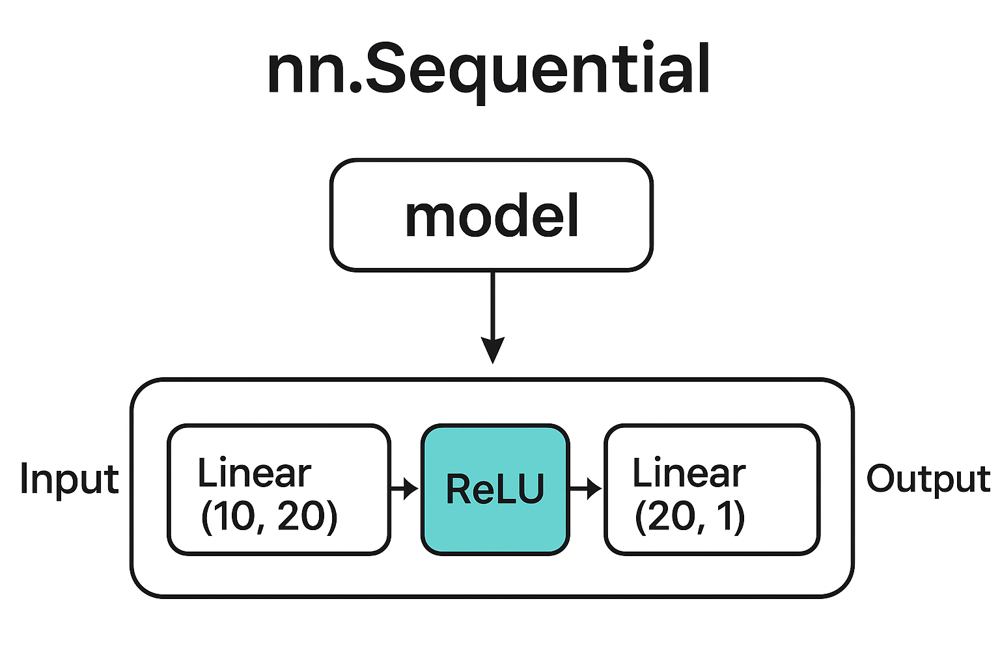

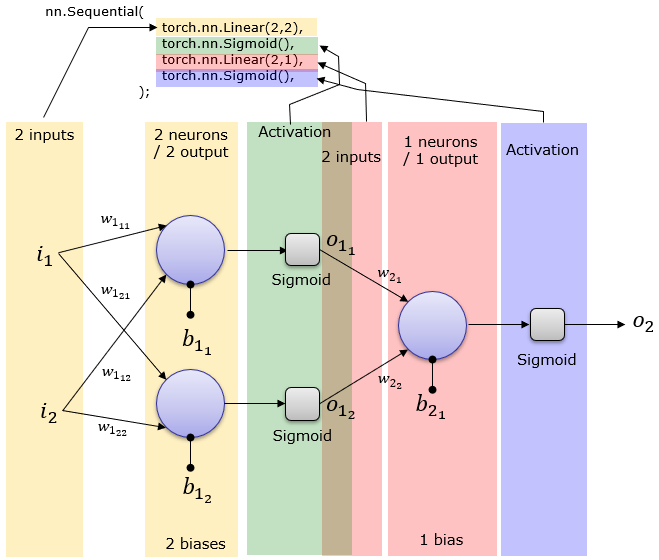

### Definición de la Arquitectura CNN para Clasificación de Espectrogramas de Mel

Nuestra red recibirá una imagen con dimensiones `(1, 64, 32)` (1 canal, 64 mel-bins de alto y 32 frames de tiempo de ancho) y devolverá la probabilidad de pertenecer a la clase de grito (clasificación binaria).

In [ ]:
class ScreamDetectorCNN(nn.Module):
    def __init__(self, num_classes=1):
        super().__init__()

        # Bloque 1: Entrada (Batch, 1, n_mels, time_steps)
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Bloque 2
        self.conv2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Bloque 3
        self.conv3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Bloque 4
        self.conv4 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)) # Reduce (128, H, W) -> (128, 1, 1) sin importar el largo del audio
        )

        # Clasificador binario
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes) # Salida sin sigmoide (usar BCEWithLogitsLoss)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        return self.classifier(x)

# Crear instancia del modelo y mostrar su estructura
model = ScreamDetectorCNN()
model = model.to(device)
print(model)

ScreamDetectorCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv4): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(

## Particion del dataset

In [ ]:
# Dividir el dataset en Entrenamiento (80%) y Validación (20%)
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(audio_dataset_ready))
val_size = len(audio_dataset_ready) - train_size

dataset_train, dataset_val = random_split(audio_dataset_ready, [train_size, val_size], generator=generator)

# DataLoaders
batch_size = 32
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True, drop_last=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size, shuffle=False)

print(f"Muestras de entrenamiento: {len(dataset_train)} (Lotes: {len(dataloader_train)})")
print(f"Muestras de validación: {len(dataset_val)} (Lotes: {len(dataloader_val)})")

Muestras de entrenamiento: 800 (Lotes: 25)
Muestras de validación: 200 (Lotes: 7)


In [ ]:
criterion = nn.BCEWithLogitsLoss() # para clasificacion de una clase.

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

## Entrenamiento

In [ ]:
from tqdm.notebook import tqdm

num_epochs = 20
best_val_loss = float('inf')

train_loses = []
train_accs = []

val_loses = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    # Barra de progreso del entrenamiento
    train_bar = tqdm(
        dataloader_train,
        desc=f"Época [{epoch+1}/{num_epochs}] Train",
        leave=False
    )

    for images, labels in train_bar:
        # Mover datos al dispositivo y ajustar la etiqueta para BCEWithLogitsLoss
        images = images.to(device)
        labels = labels.to(device).float().unsqueeze(1)  # Ajuste de tamaño a [batch_size, 1] y tipo float

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        # Para binary logits, el umbral es > 0.0 (equivalente a Probabilidad > 0.5)
        preds = (outputs > 0.0).float()

        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

        # Actualizar información de la barra
        train_bar.set_postfix(loss=f" {loss.item():.4f}")

    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = correct_train / total_train

    # FASE DE VALIDACIÓN
    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    val_bar = tqdm(dataloader_val, desc="Validación", leave=False)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            preds = (outputs > 0.0).float()

            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

            val_bar.set_postfix(loss=f" {loss.item():.4f}")

    epoch_val_loss = running_val_loss / total_val
    epoch_val_acc = correct_val / total_val

    #scheduler.step(epoch_val_loss)

    train_loses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    val_loses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)

    print(
        f"Época [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {epoch_train_loss:.4f} - Acc: {epoch_train_acc:.4f} "
        f"| Val Loss: {epoch_val_loss:.4f} - Acc: {epoch_val_acc:.4f}"
    )

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), 'best_model.pth')
        print(" -> ¡Nuevo mejor modelo guardado!")

Época [1/20] Train:   0%|          | 0/25 [00:00<?, ?it/s]

Validación:   0%|          | 0/7 [00:00<?, ?it/s]

Época [1/20] | Train Loss: 0.6814 - Acc: 0.5475 | Val Loss: 0.6688 - Acc: 0.6650
 -> ¡Nuevo mejor modelo guardado!


Época [2/20] Train:   0%|          | 0/25 [00:00<?, ?it/s]

Validación:   0%|          | 0/7 [00:00<?, ?it/s]

Época [2/20] | Train Loss: 0.6598 - Acc: 0.6150 | Val Loss: 0.6491 - Acc: 0.6200
 -> ¡Nuevo mejor modelo guardado!


... (50 outputs left out)

Época [19/20] | Train Loss: 0.4346 - Acc: 0.8125 | Val Loss: 0.4828 - Acc: 0.7500


Época [20/20] Train:   0%|          | 0/25 [00:00<?, ?it/s]

Validación:   0%|          | 0/7 [00:00<?, ?it/s]

Época [20/20] | Train Loss: 0.4304 - Acc: 0.8125 | Val Loss: 0.4515 - Acc: 0.7650


# Resultados

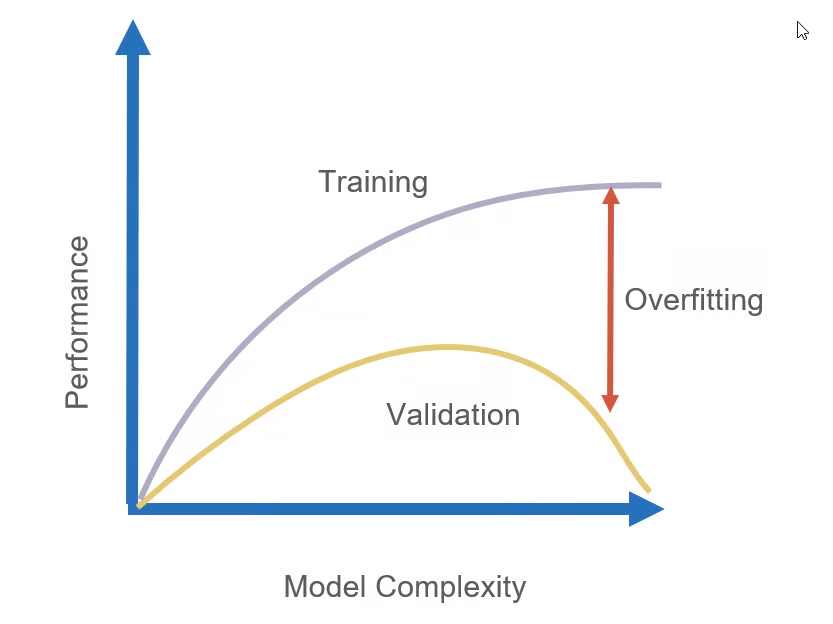

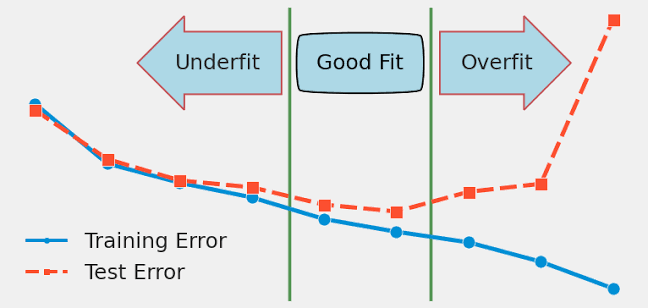

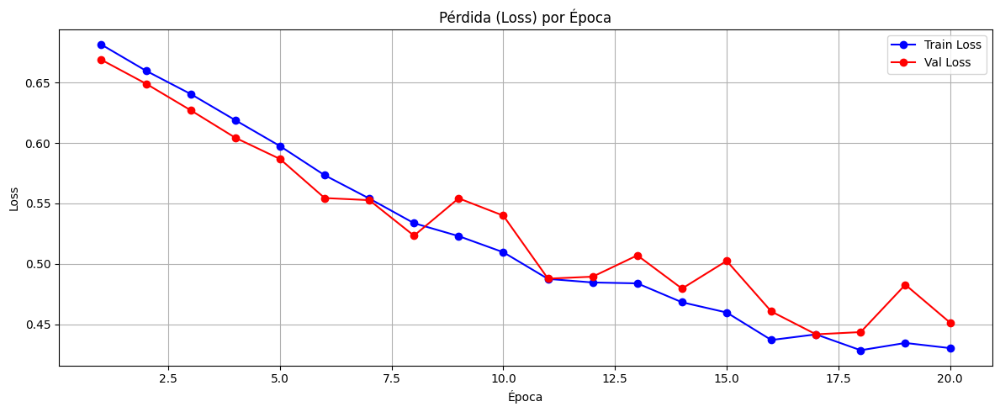

In [ ]:
# Definimos dinámicamente el rango de épocas basándonos en los datos reales recolectados
epochs = range(1, len(train_loses) + 1)

# Crear gráficas
plt.figure(figsize=(12, 5))
# Gráfica de Loss
plt.plot(epochs, train_loses, 'b-o', label='Train Loss')
plt.plot(epochs, val_loses, 'r-o', label='Val Loss')
plt.title('Pérdida (Loss) por Época')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Instanciar el modelo y cargar los mejores pesos guardados
best_model = ScreamDetectorCNN()
best_model.load_state_dict(torch.load('best_model.pth', map_location=device))
best_model = best_model.to(device)
best_model.eval()

indice_prueba = 400 # 500 audios gritar - 500 audio de no gritar
#indice_prueba = get_not_screaming_idx(total_dataset)

# Obtenemos los datos sin procesar para poder reproducir el audio original
item_original = total_dataset[indice_prueba]
audio_original = item_original['waveform']
sr_original = item_original['sample_rate']
etiqueta_real_str = item_original['label']

# 3. Obtener el espectrograma procesado usando CustomAudioDataset
espectrograma, etiqueta_real = audio_dataset_ready[indice_prueba]

# Añadimos la dimensión de lote (batch dimension) y lo enviamos al dispositivo
input_tensor = espectrograma.unsqueeze(0).to(device)

# 4. Realizar la predicción
with torch.no_grad():
    logits = best_model(input_tensor)
    # Aplicamos la función Sigmoide para obtener una probabilidad entre 0 y 1
    probabilidad = torch.sigmoid(logits).item()

# Determinar la clase predicha basándonos en el umbral de 0.5
prediccion = "Screaming (Grito)" if probabilidad >= 0.5 else "NotScreaming (No Grito)"

print(f"--- RESULTADOS DE LA PRUEBA (CASO: NO GRITO) ---")
print(f"Índice del audio utilizado: {indice_prueba}")
print(f"Etiqueta Real en Dataset: {etiqueta_real_str} (Clase {etiqueta_real})")
print(f"Predicción del Modelo: {prediccion}")
print(f"Probabilidad de que sea Grito: {probabilidad * 100:.2f}%")
print(f"--------------------------------\n")

# Escuchar el audio original
print("Reproduce el audio para verificar que no es un grito:")
display(IPython.display.Audio(audio_original.numpy(), rate=sr_original))

--- RESULTADOS DE LA PRUEBA (CASO: NO GRITO) ---
Índice del audio utilizado: 400
Etiqueta Real en Dataset: Screaming (Clase 1)
Predicción del Modelo: Screaming (Grito)
Probabilidad de que sea Grito: 97.57%
--------------------------------

Reproduce el audio para verificar que no es un grito:


                         precision    recall  f1-score   support

NotScreaming (No Grito)       0.78      0.86      0.82       113
      Screaming (Grito)       0.79      0.68      0.73        87

               accuracy                           0.78       200
              macro avg       0.78      0.77      0.77       200
           weighted avg       0.78      0.78      0.78       200



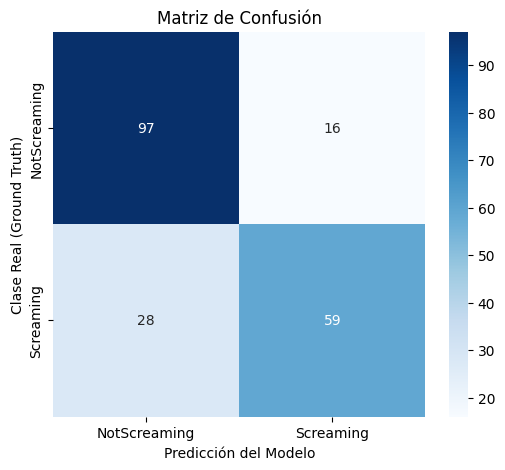

In [ ]:
def evaluar_modelo_completo(modelo_ruta, dataloader):
    # 1. Instanciar el modelo con la arquitectura y cargar los mejores pesos
    eval_model = ScreamDetectorCNN()
    eval_model.load_state_dict(torch.load(modelo_ruta, map_location=device))
    eval_model = eval_model.to(device)
    eval_model.eval()

    target_totales = []
    predicciones_totales = []

    # 2. Realizar predicciones sobre todo el dataset de prueba
    with torch.no_grad():
        for imagenes, etiquetas in dataloader:
            imagenes = imagenes.to(device)

            # Ejecutar modelo
            salidas = eval_model(imagenes)
            # Aplicar sigmoide para obtener probabilidad
            probabilidades = torch.sigmoid(salidas)
            # Clasificar (1 si prob >= 0.5, sino 0)
            predicciones = (probabilidades >= 0.5).float()

            # Guardar resultados en listas CPU para scikit-learn
            target_totales.extend(etiquetas.cpu().numpy())
            predicciones_totales.extend(predicciones.squeeze(1).cpu().numpy())

    # 3. Calcular y mostrar reporte de métricas clásicas
    print(classification_report(
        target_totales,
        predicciones_totales,
        target_names=['NotScreaming (No Grito)', 'Screaming (Grito)']
    ))

    # 4. Generar y graficar la Matriz de Confusión
    cm = confusion_matrix(target_totales, predicciones_totales)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['NotScreaming', 'Screaming'],
        yticklabels=['NotScreaming', 'Screaming']
    )
    plt.title('Matriz de Confusión')
    plt.ylabel('Clase Real (Ground Truth)')
    plt.xlabel('Predicción del Modelo')
    plt.show()

# Ejecutar la evaluación con los mejores pesos guardados
evaluar_modelo_completo('best_model.pth', dataloader_val)

# Bibliografia

- Openslr.org. (s. f.). https://www.openslr.org/12
- PyTorch-Adventures/PyTorch for Audio/Intro to Audio Processing/intro_to_audio_processing.ipynb at main · priyammaz/PyTorch-Adventures. (s. f.). GitHub. https://github.com/priyammaz/PyTorch-Adventures/blob/main/PyTorch%20for%20Audio/Intro%20to%20Audio%20Processing/intro_to_audio_processing.ipynb

- Sistemas Inteligentes. (2020, 19 noviembre). Transformada Discreta de Fourier. Análisis de audio en tiempo real con Python (Scipy) [Vídeo]. YouTube. https://www.youtube.com/watch?v=5QPdlTg1z-I

- Human Screaming Detection Dataset. (2023, November 30). https://www.kaggle.com/datasets/whats2000/human-screaming-detection-dataset/data

- Huang, J.-T., Li, J., & Gong, Y. (2015). An analysis of convolutional neural networks for speech recognition. Microsoft Corporation. https://www.microsoft.com/en-us/research/wp-content/uploads/2015/04/Detailed-Analysis-of-Convolutional-Neural-Networks-for-Speech-Recognitio_Final.pdf